## Dataset overview and preprocessing

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'data/products.parquet').exists(): ROOT = ROOT.parent
assert (ROOT / 'data/products.parquet').exists(), 'Start in the repository or evaluation directory.'
sys.path.insert(0, str(ROOT))
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['TRANSFORMERS_OFFLINE'] = '1'
os.environ['HF_HOME'] = str(ROOT / '.cache/huggingface')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import hashlib, json, faiss, torch
from unittest.mock import patch
from backend.image_search import ImageSearch, CONFIG, INDEX_DIR, digest, MODEL, REVISION
products = pd.read_parquet(ROOT / 'data/products.parquet')
products['sample_key'] = products.parent_asin.map(lambda x: hashlib.sha256(('image-v1:' + x).encode()).hexdigest())
sample = products.sort_values('sample_key').groupby('main_category', sort=True).head(2)
assert len(sample) == 24
display(pd.DataFrame({'catalog products': [len(products)], 'query images': [len(sample)], 'categories': [sample.main_category.nunique()]}))
display(sample[['main_category', 'parent_asin', 'title']].reset_index(drop=True))

C:\Users\User\Projects\Relevia\.pixi\envs\default\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[transformers] `CLIPImageProcessor` requires torchvision (not installed); falling back to `CLIPImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `CLIPImageProcessorPil` directly to silence this warning.


,catalog products,query images,categories
0,1120,24,12


,main_category,parent_asin,title
0,TV & Video Players,B09RMRS767,"DVD Players for TV, HD DVD Player, Compact Hom..."
1,Vehicle Electronics & GPS,B00CDI5CJ6,"Jensen Speaker, Green, 8-Inch (C8R4)"
2,Data Storage,B004YISMKO,LaCie d2 Quadra Hard Disk 1 TB eSATA/FireWire8...
3,Data Storage,B09J8ZFZ48,Western Digital 1TB WD Blue SA510 SATA Interna...
4,Power & Lighting,B0BST8S2CY,Designer Series 6-ft 3-Outlet USB Surge Protec...
5,Cameras & Photography,B00HNOOVGK,Fujifilm XP70 16 MP Digital Camera with 2.7-In...
6,Vehicle Electronics & GPS,B07BMBLWJG,Sound Storm Laboratories EV2500M Evolution 250...
7,Computers & Components,B099PCMMM9,Kingston FURY Impact 32GB (2x16GB) 3200MT/s DD...
8,Headphones & Earbuds,B00BEBAIAQ,Sony MDR-EX37B/BLK Earbud Style Headphones
9,Networking,B07ZYRW5YK,"BENFEI 2 Pack USB 3.0 Hub 4-Port, Ultra-Slim U..."


## Load CLIP and the existing FAISS index

In [2]:
# Validate the cache and refuse to rebuild it.
def load_existing(self):
    manifest = json.loads((INDEX_DIR / 'manifest.json').read_text(encoding='utf-8'))
    assert manifest['config'] == CONFIG and manifest['entries'] == self.entries
    assert digest(INDEX_DIR / 'embeddings.npy') == manifest['vectors_sha256']
    assert digest(INDEX_DIR / 'products.faiss') == manifest['index_sha256']
    self.index = faiss.read_index(str(INDEX_DIR / 'products.faiss'))
    assert self.index.ntotal == len(self.entries) and self.index.d == CONFIG['dimension']
    self.cache_hit = True
with patch.object(ImageSearch, 'load_or_build', load_existing):
    image_search = ImageSearch()
image_search.load_model()
print(f'{MODEL}, revision {REVISION}; FAISS {image_search.index.ntotal} × {image_search.index.d}; device {image_search.device}')


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 9287.49it/s]

openai/clip-vit-base-patch32, revision 3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268; FAISS 1120 × 512; device cpu


## Fresh image inference and identity evaluation

,P@5,P@10,Recall@5,Recall@10,Hit@5,Hit@10,MRR@10,NDCG@10
0,0.2,0.1,1.0,1.0,1.0,1.0,1.0,1.0


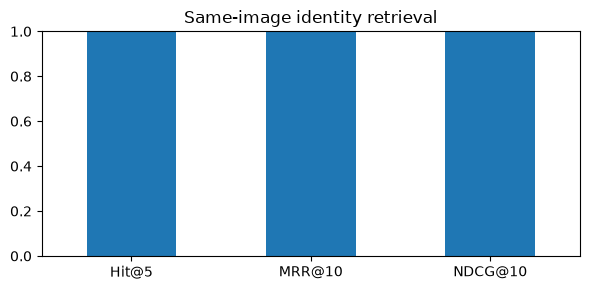

In [3]:
ranks = []
for row in sample.itertuples():
    # Encoding the same bytes directly models the external-copy search path.
    vector = image_search.encode([ROOT / row.image_path])
    scores, indices = image_search.index.search(np.ascontiguousarray(vector), 10)
    ids = [image_search.products[int(i)]['parent_asin'] for i in indices[0]]
    ranks.append(ids.index(row.parent_asin) + 1 if row.parent_asin in ids else np.inf)
ranks = np.array(ranks)
result = pd.DataFrame([{'P@5': (ranks<=5).mean()/5, 'P@10': (ranks<=10).mean()/10,
                        'Recall@5': (ranks<=5).mean(), 'Recall@10': (ranks<=10).mean(),
                        'Hit@5': (ranks<=5).mean(), 'Hit@10': (ranks<=10).mean(),
                        'MRR@10': (1/ranks).mean(), 'NDCG@10': (1/np.log2(ranks+1)).mean()}])
display(result.round(3))
pd.Series({'Hit@5': (ranks<=5).mean(), 'MRR@10': (1/ranks).mean(),
           'NDCG@10': (1/np.log2(ranks+1)).mean()}).plot.bar(rot=0, ylim=(0,1), figsize=(6,3), title='Same-image identity retrieval')
plt.tight_layout(); plt.show()

## Interpretation

Identical indexed images make this an optimistic identity test. Visual relevance requires independent image–product judgments.